Manual Linear Regression

Re-implementation of Example 4.2

Set the Data: inputs and outputs

In [1]:
from bleach.sanitizer import ALLOWED_TAGS

X = [0, 1, 2, 3, 4]
y = [0, 0.3, 0.75, 1, 2]

In [2]:
import pandas as pd

In [3]:
data = {
    'X': X,
    'y': y
}
df = pd.DataFrame(data)

In [4]:
import seaborn as sns

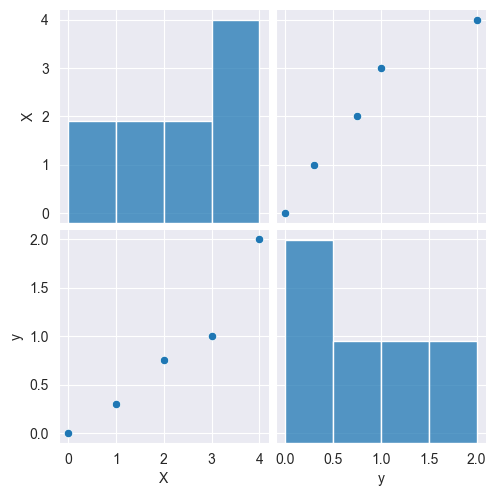

In [5]:
sns.pairplot(df)

The algorithm

Set values

In [6]:
sum_X = sum(X)
sum_y = sum(y)
n = len(X)

In [7]:
sum_X2 = 0.0
sum_Xy = 0.0

for i in range(len(X)):
    sum_X2 += X[i]**2
    sum_Xy += X[i]*y[i]

Combining for formulas

In [8]:
# y = b_0 + b_1*x

In [9]:
b_0 = (sum_y * sum_X2 - sum_X * sum_Xy) / (n * sum_X2 - sum_X ** 2)

In [10]:
b_1 = (n * sum_Xy - sum_X * sum_y) / (n * sum_X2 - sum_X ** 2)

In [11]:
b_1

0.47

In [12]:
b_0

-0.13

testing

In [13]:
# given a point 5, we could predict something around 2

In [14]:
X_test = 3
b_0 + X_test * b_1

1.2799999999999998

In [15]:
# looks good - let's move onto another dimension

Multiple Regression

In [16]:
import numpy as np

Set the Data

In [68]:
X = [(0,0), (1,2), (2,4), (3,0), (4,1)]
y = [0, 0.3, 0.75, 1, 2]

In [69]:
X_array = np.array(X)
x_1_array = X_array[:, 0]
x_2_array = X_array[:, 1]

In [70]:
y_array = np.array(y)

In [71]:
X_array = np.array(X)
x_1_array = X_array[:, 0]
x_2_array = X_array[:, 1]

ones = np.ones((len(X), 1))

A = np.column_stack((ones, x_1_array, x_2_array))

df.iloc[:,1:].values

array([[0.  ],
       [0.3 ],
       [0.75],
       [1.  ],
       [2.  ]])

In [72]:
A = np.column_stack((ones, x_1_array, x_2_array))

In [73]:
A

array([[1., 0., 0.],
       [1., 1., 2.],
       [1., 2., 4.],
       [1., 3., 0.],
       [1., 4., 1.]])

In [74]:
A_T = A.transpose()

In [82]:
type(A_T)

numpy.ndarray

In [83]:
def get_linear_regression(A, y):
    A_T = A.transpose()
    return np.dot(np.dot(np.linalg.inv(np.dot(A_T, A)), A_T),y)

In [85]:
B = get_linear_regression(A,y)

In [86]:
B

array([-0.12125,  0.47   , -0.00625])

In [ ]:
# tesing on some points (0,.5) which should give just over 0 and (4,2) which should give just over 2

In [99]:
def calculate_result (input, B):
    result = B[0]
    for i in range(len(B)-1):
        result += B[i+1] * input[i]
    return result


In [101]:
result = calculate_result([0, .5], B)

In [102]:
result

np.float64(-0.12437499999999985)

In [87]:
B[0] + 0 * B[1] + 0.5 * B[2]

np.float64(-0.12437499999999985)

In [31]:
B[0] + 4 * B[1] + 2 * B[2]

np.float64(1.7462499999999999)

Alright, worked alright

Let's try on this data set

In [120]:
df = pd.read_csv('ENB2012_data.csv')
X = df.iloc[:, :-2]  # All columns except last 2 (targets)
y = df.iloc[:, -2:]  # Last 2 columns (Y1: Heating Load, Y2: Cooling Load)

In [121]:
df

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28
...,...,...,...,...,...,...,...,...,...,...
763,0.64,784.0,343.0,220.50,3.5,5,0.4,5,17.88,21.40
764,0.62,808.5,367.5,220.50,3.5,2,0.4,5,16.54,16.88
765,0.62,808.5,367.5,220.50,3.5,3,0.4,5,16.44,17.11
766,0.62,808.5,367.5,220.50,3.5,4,0.4,5,16.48,16.61


In [122]:
X

,X1,X2,X3,X4,X5,X6,X7,X8
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0
...,...,...,...,...,...,...,...,...
763,0.64,784.0,343.0,220.50,3.5,5,0.4,5
764,0.62,808.5,367.5,220.50,3.5,2,0.4,5
765,0.62,808.5,367.5,220.50,3.5,3,0.4,5
766,0.62,808.5,367.5,220.50,3.5,4,0.4,5


In [ ]:
# Looks like there are 2 target variables, so let's do linear regression
# seperately for each

In [106]:
y

,Y1_Heating_Load,Y2_Cooling_Load
0,51.678327,39.765927
1,60.989645,41.718607
2,53.987327,45.090329
3,53.691735,47.686489
4,47.849974,34.822909
...,...,...
763,52.514200,41.567917
764,46.494317,39.208148
765,52.817117,38.591630
766,49.215731,40.985964


In [107]:
y_h = np.array(y.iloc[:,0])
y_c = np.array(y.iloc[:,1])

In [108]:
A = np.hstack([np.ones((len(X), 1)), X.values])

In [109]:
A

array([[1.00000000e+00, 7.54834443e-01, 6.15072034e+02, ...,
        2.00000000e+00, 0.00000000e+00, 2.00000000e+00],
       [1.00000000e+00, 9.62257150e-01, 7.55949648e+02, ...,
        4.00000000e+00, 1.00000000e-01, 3.00000000e+00],
       [1.00000000e+00, 8.83517819e-01, 5.47025731e+02, ...,
        2.00000000e+00, 1.00000000e-01, 5.00000000e+00],
       ...,
       [1.00000000e+00, 8.25160287e-01, 5.94651456e+02, ...,
        3.00000000e+00, 2.50000000e-01, 1.00000000e+00],
       [1.00000000e+00, 8.94485127e-01, 6.36083436e+02, ...,
        2.00000000e+00, 4.00000000e-01, 2.00000000e+00],
       [1.00000000e+00, 9.35635629e-01, 5.50334511e+02, ...,
        4.00000000e+00, 4.00000000e-01, 2.00000000e+00]], shape=(768, 9))

In [110]:
B_h = get_linear_regression(A,y_h)

In [112]:
B_h

array([ 1.48341745e+01,  3.03776922e+01,  2.02379907e-02,  1.43797591e-03,
       -1.83622906e-03,  1.86011216e-02, -1.20048870e-01,  4.25083950e-01,
       -8.64774090e-02])

In [113]:
B_c = get_linear_regression(A,y_c)

In [114]:
B_c

array([ 9.73170576e+00,  2.49138209e+01,  1.47702687e-02,  1.12414861e-03,
       -4.34617739e-04, -6.72494912e-04,  2.90691026e-02,  6.74639265e-01,
        4.67452825e-03])

Should go back and turn this into train and test split

should then test on the test data

do that by also adding code to find error

In [ ]:
result = calculate_result([0, .5], B)